(mmm_funnel_joint_vs_two_stage)=
# Joint or Two-Stage? Estimating a Brand Funnel Through Branded Search

Brand advertising such as video reaches sales by two routes:

- some people convert soon after seeing an ad;
- others become interested in the brand, search for it, and convert later.

The second route runs through **brand demand**, which no dataset records directly. Analysts usually measure it with branded query volume, the number of searches for the brand name. A funnel-aware MMM, like the one in {ref}`mmm_funnel_mueffect`, models both routes, so it can tell how much of a brand campaign's effect arrives through search.

Such a model has two equations: one for how advertising moves brand demand, and one for how demand and media move sales. There are two ways to estimate them:

- Two-stage: fit the demand equation on branded queries first, then fit the sales equation with a demand series as an input, and chain the two.
- One-stage (joint): fit both equations together, as one model with a likelihood for branded queries and one for sales.

This notebook makes the case for the joint model. We simulate data where the true effects are known and give both strategies the same model specification, so any difference comes from how the model is estimated. The comparison builds up in three layers:

1. branded queries measure demand exactly;
2. branded queries measure demand with noise;
3. on top of that, the sales equation misses a driver.

What the simulations show:

- If branded queries measured demand perfectly, the two strategies would give the same answers and recommend the same budget. The joint model would have nothing to add.
- Real query data are noisy. Feeding raw queries into the sales equation, a common shortcut, understates how much of a brand campaign's effect arrives through search, whichever strategy you use. Estimating demand first removes that bias.
- Once demand is estimated, the joint model is about as accurate as a two-stage model, and the uncertainty it reports is closer to its real error. Its budget advice loses slightly fewer conversions on average.
- The joint model is much safer when the sales equation leaves something out. Its budget advice then lost 1.6% of conversions on average and 8% in the worst case, against 5% and 27% for two stages.
- A joint model gives the budget optimizer the whole path from brand media through demand to sales. With two stages, the optimizer needs that path added by hand; without it, the plan lost 28% of the achievable conversions.

## Prepare Notebook

In [1]:
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pymc.dims as pmd
from pydantic import InstanceOf
from scipy import stats
from scipy.interpolate import BSpline

from pymc_marketing.mmm import (
    AdstockTransformation,
    GeometricAdstock,
    LogisticSaturation,
    SaturationTransformation,
)
from pymc_marketing.mmm.additive_effect import DataVarMuEffect
from pymc_marketing.mmm.data_conversion import to_mmm_dataset
from pymc_marketing.mmm.mmm import MMM

warnings.filterwarnings("ignore", category=FutureWarning)

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%config InlineBackend.figure_format = "retina"

In [2]:
seed: int = sum(map(ord, "joint funnel"))
rng: np.random.Generator = np.random.default_rng(seed=seed)

N_WEEKS = 156
L_MAX = 8
CHANNELS = ["video", "search", "display"]

## The funnel

The data follow the causal structure in the diagram below.

- Upper-funnel media raise brand demand, and brand demand drives conversions. For upper-funnel media, demand is a **mediator**: part of their effect travels through it.
- Organic interest moves brand demand too.
- Branded queries measure brand demand. They rise and fall with it but do not cause conversions.
- Performance channels such as search and display follow brand demand: search ads show on branded searches, and display spend grows with the audiences built from people who search. Demand moves both their spend and conversions, so it is a **confounder** for these channels.

A standard MMM with a single equation cannot handle both roles. Leaving demand out over-credits search and display, which get the credit for demand they only follow. Adding branded queries as an ordinary input blocks the path through demand and under-credits upper-funnel media. Modeling the demand and sales equations separately fixes both, at the cost of estimating more effects. In the simulation below, the upper-funnel channel is video.

In [3]:
def draw_dag(ax, nodes, edges, title=None):
    """Draw a causal diagram: observed nodes in gray, latent nodes in white."""
    artists = {}
    for name, (x, y, label, observed) in nodes.items():
        artists[name] = ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            fontsize=12,
            bbox={
                "boxstyle": "round,pad=0.4",
                "facecolor": "#d9d9d9" if observed else "white",
                "edgecolor": "black",
            },
        )
    for start, end, style, rad in edges:
        ax.annotate(
            "",
            xy=(0.5, 0.5),
            xycoords=artists[end],
            xytext=(0.5, 0.5),
            textcoords=artists[start],
            arrowprops={
                "arrowstyle": "-|>",
                "linestyle": style,
                "linewidth": 1.3,
                "color": "black",
                "patchA": artists[start].get_bbox_patch(),
                "patchB": artists[end].get_bbox_patch(),
                "shrinkA": 2,
                "shrinkB": 2,
                "connectionstyle": f"arc3,rad={rad}",
            },
        )
    if title:
        ax.set_title(title)
    ax.axis("off")


def frame_box(ax, x0, y0, x1, y1, label):
    """Dashed frame marking which data a fit sees."""
    ax.add_patch(
        plt.Rectangle(
            (x0, y0), x1 - x0, y1 - y0, fill=False, linestyle="--", color="#52514e"
        )
    )
    ax.text(x0 + 0.08, y1 - 0.08, label, va="top", fontsize=11, color="#52514e")

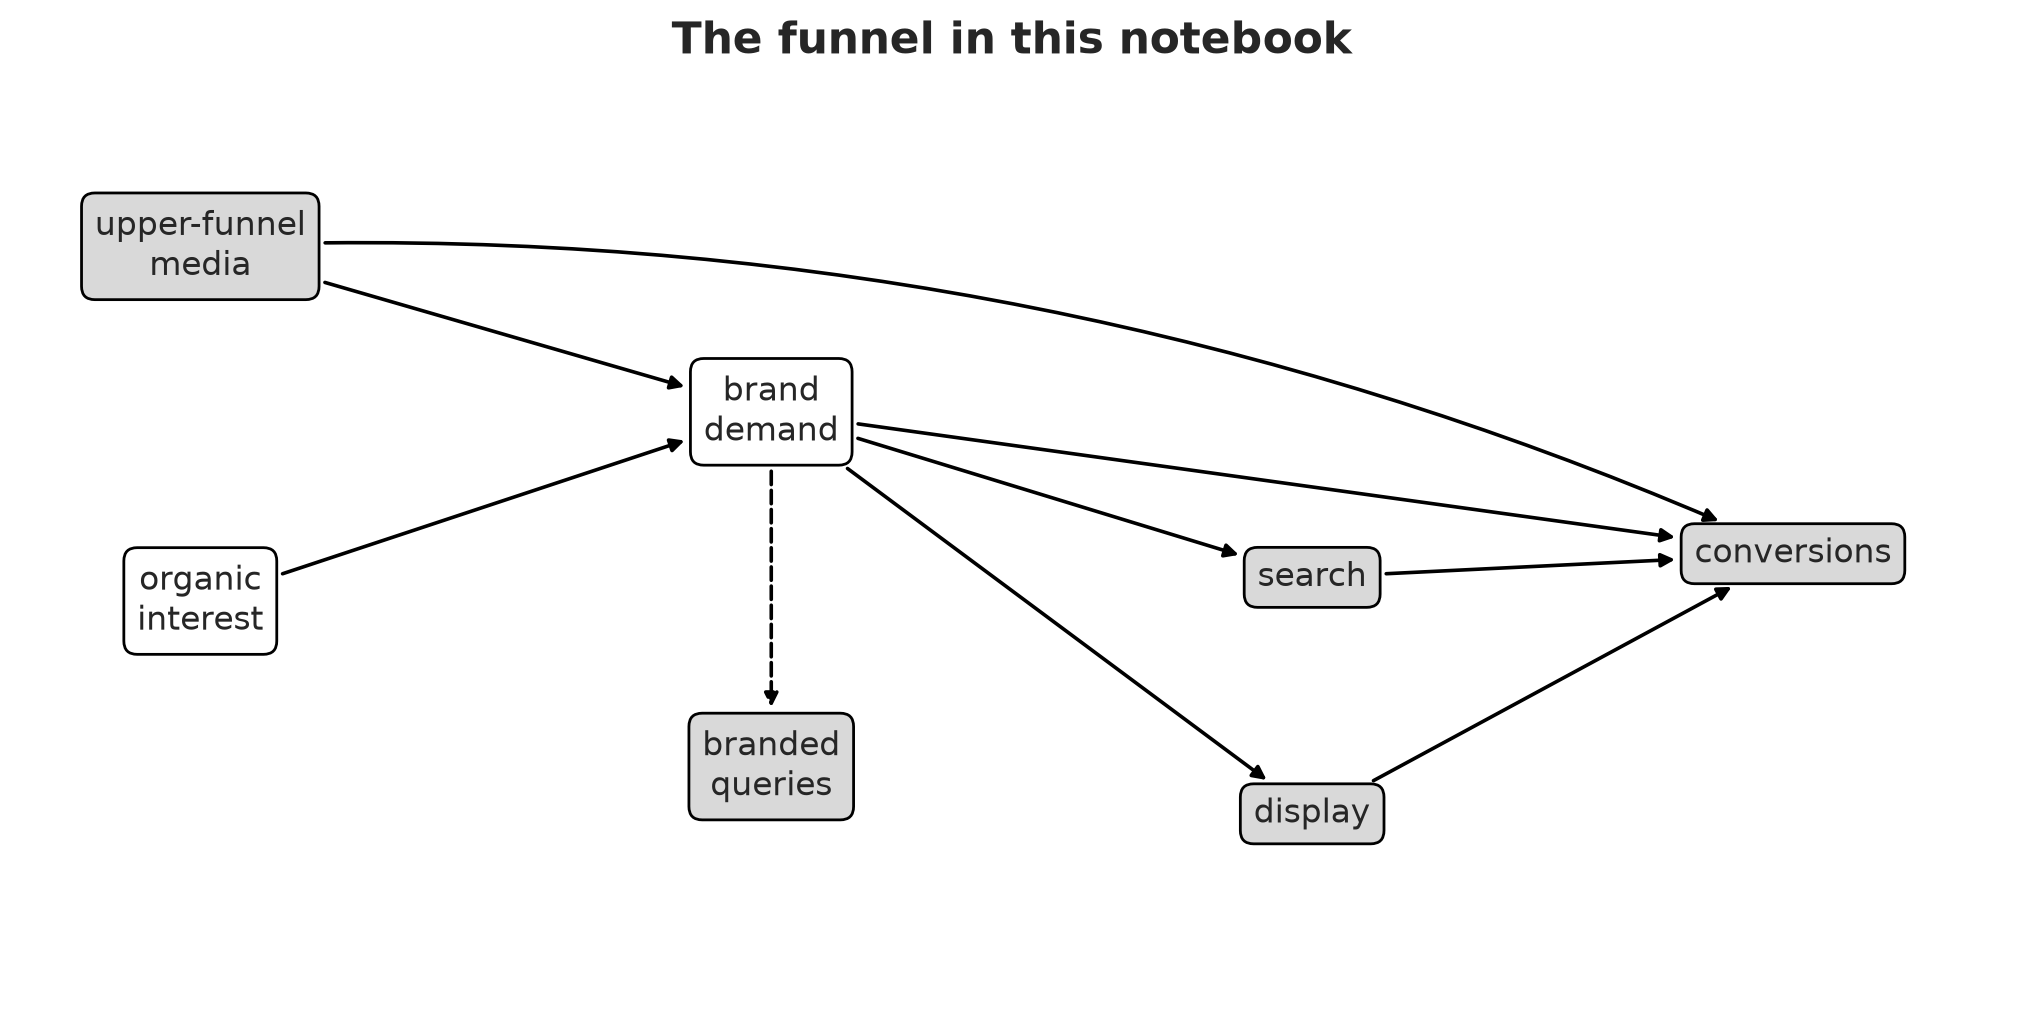

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
draw_dag(
    ax,
    nodes={
        "video": (0.0, 2.6, "upper-funnel\nmedia", True),
        "organic": (0.0, 1.1, "organic\ninterest", False),
        "demand": (1.9, 1.9, "brand\ndemand", False),
        "queries": (1.9, 0.4, "branded\nqueries", True),
        "search": (3.7, 1.2, "search", True),
        "display": (3.7, 0.2, "display", True),
        "conversions": (5.3, 1.3, "conversions", True),
    },
    edges=[
        ("video", "demand", "-", 0),
        ("organic", "demand", "-", 0),
        ("demand", "queries", "--", 0),
        ("video", "conversions", "-", -0.12),
        ("demand", "conversions", "-", 0),
        ("demand", "search", "-", 0),
        ("demand", "display", "-", 0),
        ("search", "conversions", "-", 0),
        ("display", "conversions", "-", 0),
    ],
)
ax.set(xlim=(-0.6, 6.0), ylim=(-0.6, 3.3))
fig.suptitle("The funnel in this notebook", fontsize=16, fontweight="bold");

**Caption:** The funnel used throughout the notebook. Gray boxes are observed in the data; white boxes are latent. The dashed arrow is a measurement: branded queries read brand demand.

## One-stage and two-stage estimation

Both strategies use the same two equations:

- the **demand equation**: brand demand = baseline + video's lift (adstock and saturation) + smooth organic interest, measured by branded queries;
- the **sales equation**: conversions = intercept + effect of each channel + effect of brand demand.

Two-stage fits the demand equation on branded queries first (stage 1), then the sales equation with a demand series as a fixed input (stage 2). Video's effect through demand is stage 1's lift times stage 2's effect of demand. Pairing posterior draw $i$ of stage 1 with draw $i$ of stage 2 carries stage 1's uncertainty into that product. Each stage is a small model you can fit and check on its own, which is how {ref}`mmm_intro_upper_funnel` and {ref}`mmm_upper_funnel_causal_approach` approach the same problem.

The joint model puts both equations and their likelihoods into one model and fits them at once. Conversions can then inform the demand equation, and the posterior keeps track of how the parameters of the two equations depend on each other.

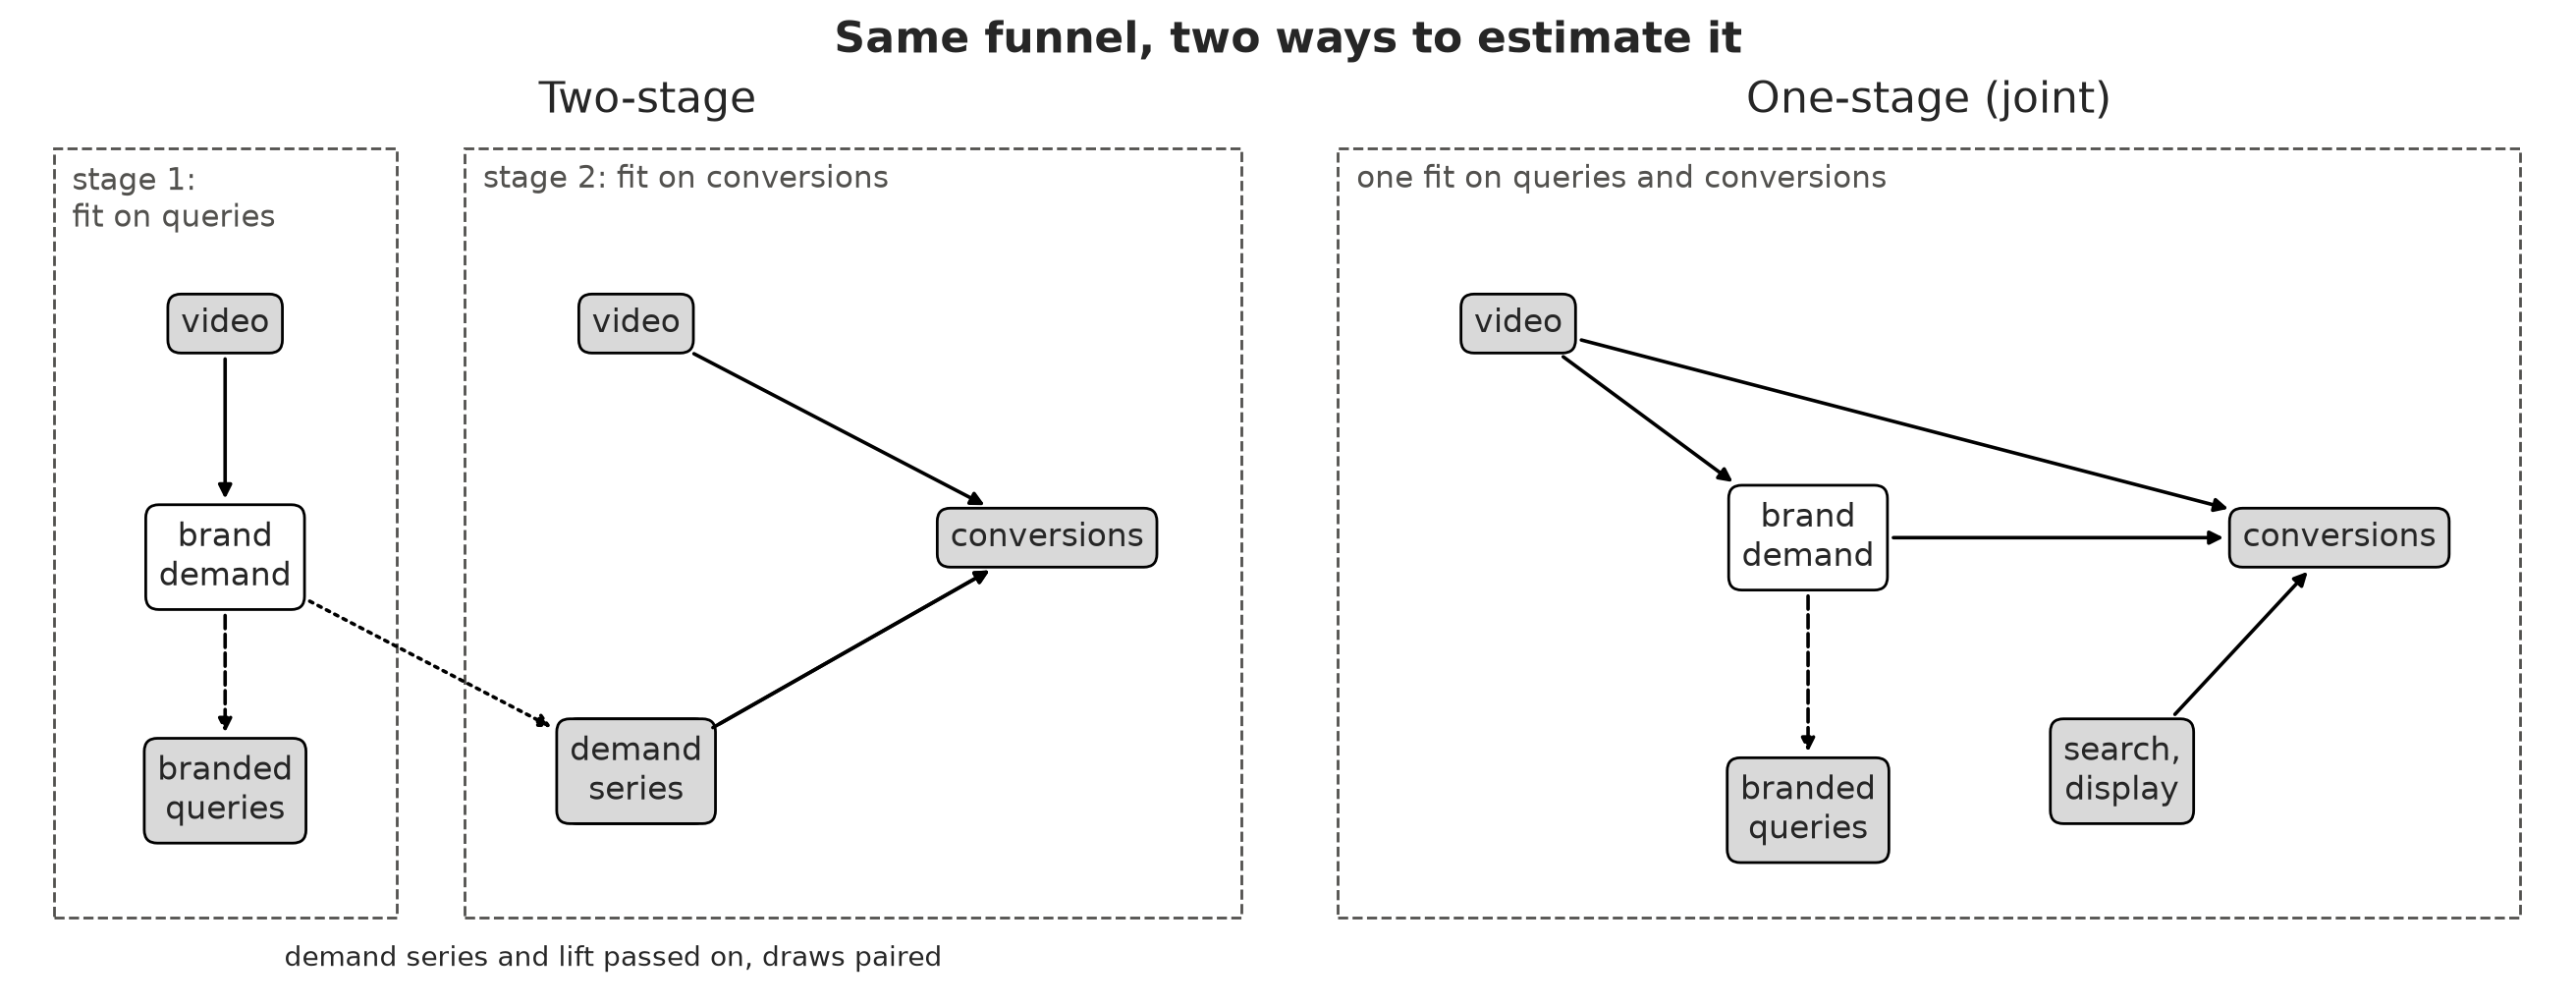

In [5]:
fig, (ax_two, ax_one) = plt.subplots(1, 2, figsize=(13, 5))

draw_dag(
    ax_two,
    nodes={
        "video1": (0.3, 2.3, "video", True),
        "demand1": (0.3, 1.1, "brand\ndemand", False),
        "queries1": (0.3, -0.1, "branded\nqueries", True),
        "video2": (2.1, 2.3, "video", True),
        "others2": (2.1, 0.0, "search,\ndisplay", True),
        "series2": (2.1, 0.0, "demand\nseries", True),
        "conversions2": (3.9, 1.2, "conversions", True),
    },
    edges=[
        ("video1", "demand1", "-", 0),
        ("demand1", "queries1", "--", 0),
        ("video2", "conversions2", "-", 0),
        ("others2", "conversions2", "-", 0),
        ("series2", "conversions2", "-", 0),
        ("demand1", "series2", ":", 0),
    ],
    title="Two-stage",
)
frame_box(ax_two, -0.45, -0.75, 1.05, 3.2, "stage 1:\nfit on queries")
frame_box(ax_two, 1.35, -0.75, 4.75, 3.2, "stage 2: fit on conversions")
ax_two.set(xlim=(-0.6, 4.9), ylim=(-1.1, 3.3))
ax_two.text(2.0, -1.0, "demand series and lift passed on, draws paired", ha="center")

draw_dag(
    ax_one,
    nodes={
        "video": (0.3, 2.3, "video", True),
        "demand": (1.5, 1.2, "brand\ndemand", False),
        "queries": (1.5, -0.2, "branded\nqueries", True),
        "others": (2.8, 0.0, "search,\ndisplay", True),
        "conversions": (3.7, 1.2, "conversions", True),
    },
    edges=[
        ("video", "demand", "-", 0),
        ("demand", "queries", "--", 0),
        ("video", "conversions", "-", 0),
        ("demand", "conversions", "-", 0),
        ("others", "conversions", "-", 0),
    ],
    title="One-stage (joint)",
)
frame_box(ax_one, -0.45, -0.75, 4.45, 3.2, "one fit on queries and conversions")
ax_one.set(xlim=(-0.6, 4.6), ylim=(-1.1, 3.3))
fig.suptitle("Same funnel, two ways to estimate it", fontsize=16, fontweight="bold");

**Caption:** In the two-stage fit (left), stage 1 never sees conversions and stage 2 treats its demand series as known. In the joint fit (right), branded queries and conversions are both likelihoods of one model.

## When can the two differ?

Write $\theta_1$ for the parameters of the demand equation and $\theta_2$ for those of the sales equation. With branded queries $Q$ and conversions $Y$, the joint posterior is

$$
p(\theta_1, \theta_2 \mid Q, Y) \;\propto\; p(Q \mid \theta_1)\; p(Y \mid \theta_1, \theta_2, Q)\; p(\theta_1)\, p(\theta_2).
$$

If branded queries measure demand exactly, the sales equation can use the observed series $Q$ itself. Conversions then do not depend on $\theta_1$, and the posterior splits into two independent pieces:

$$
p(\theta_1, \theta_2 \mid Q, Y) = p(\theta_1 \mid Q)\; p(\theta_2 \mid Y, Q).
$$

That is exactly what two separate fits estimate, so one stage or two gives the same answer.

Real branded queries measure demand with noise: some people in the market never search, some search for other reasons, and query data often come from sampled or rounded sources. The sales equation then needs the model's estimate of demand, which depends on $\theta_1$, and conversions carry information about the demand equation. The joint model uses that information; two stages cannot, because stage 1 never sees conversions. The layers below measure how much that matters.

## Data generating process

We simulate three years of weekly data for one market. The code below defines the transformations and a function that draws a whole synthetic world from fixed true parameters. Every model in the notebook uses the same adstock and logistic saturation families as the simulation, with PyMC-Marketing's default priors.

In [6]:
def adstock(x, alpha, l_max=L_MAX):
    """Apply normalized geometric adstock, one row per value of ``alpha``."""
    alpha = np.atleast_1d(np.asarray(alpha, dtype=float))
    x = np.broadcast_to(np.asarray(x, dtype=float), (alpha.size, np.shape(x)[-1]))
    weights = alpha[:, None] ** np.arange(l_max)
    weights /= weights.sum(axis=1, keepdims=True)
    padded = np.concatenate([np.zeros((x.shape[0], l_max - 1)), x], axis=1)
    windows = np.lib.stride_tricks.sliding_window_view(padded, l_max, axis=1)
    return (windows[..., ::-1] * weights[:, None, :]).sum(axis=-1)


def saturate(x, lam):
    """Apply the logistic saturation curve (without its scale ``beta``)."""
    z = np.exp(-lam * x)
    return (1 - z) / (1 + z)


def spline_basis(n_weeks=N_WEEKS, n_knots=12, degree=3):
    """Cubic B-spline basis over the weeks, one column per basis function."""
    t = np.linspace(0, 1, n_weeks)
    inner = np.linspace(0, 1, n_knots)
    knots = np.concatenate([[0] * degree, inner, [1] * degree])
    return BSpline.design_matrix(t, knots, degree).toarray()

In [7]:
true = {
    # video -> branded query volume
    "query_baseline": 0.5,
    "adstock_hub_alpha": 0.5,
    "sat_hub_lam": 3.0,
    "sat_hub_beta": 0.6,
    # conversions
    "intercept": 1.0,
    "video_alpha": 0.4,
    "video_lam": 3.0,
    "video_beta": 0.25,
    "query_alpha": 0.3,
    "query_coef": 0.5,
    "search_alpha": 0.2,
    "search_lam": 2.0,
    "search_beta": 0.45,
    "display_alpha": 0.3,
    "display_lam": 2.5,
    "display_beta": 0.3,
    "sigma": 0.04,
}


def simulate_world(rng):
    """Simulate one synthetic world: spend, query volume, conversions, and true effects."""
    dates = pd.date_range("2023-01-02", periods=N_WEEKS, freq="W-MON")

    # Video runs in flights of 3 to 6 weeks, with little spend in between.
    video = rng.uniform(0, 4, N_WEEKS)
    week = 0
    while week < N_WEEKS:
        week += rng.integers(3, 9)
        length = rng.integers(3, 7)
        video[week : week + length] = rng.uniform(40, 90)
        week += length

    # Brand demand: baseline + video lift + smooth organic interest + weekly shocks.
    basis = spline_basis()
    organic = basis @ rng.normal(0, 0.18, basis.shape[1])
    organic -= organic.mean()
    lift = true["sat_hub_beta"] * saturate(
        adstock(video / video.max(), true["adstock_hub_alpha"])[0], true["sat_hub_lam"]
    )
    demand = true["query_baseline"] + lift + organic + rng.normal(0, 0.03, N_WEEKS)

    # Performance spend follows brand demand, plus budget changes of its own.
    def budget_changes(scale):
        e = np.zeros(N_WEEKS)
        for i in range(1, N_WEEKS):
            e[i] = 0.7 * e[i - 1] + rng.normal(0, scale)
        return e

    search = np.clip(5 + 45 * demand + budget_changes(7), 1, None)
    display = np.clip(3 + 18 * demand + budget_changes(5), 1, None)
    spend = {"video": video, "search": search, "display": display}

    media = {
        c: true[f"{c}_beta"]
        * saturate(
            adstock(spend[c] / spend[c].max(), true[f"{c}_alpha"])[0], true[f"{c}_lam"]
        )
        for c in CHANNELS
    }
    demand_path = true["query_coef"] * adstock(demand, true["query_alpha"])[0]
    conversions = (
        true["intercept"]
        + sum(media.values())
        + demand_path
        + rng.normal(0, true["sigma"], N_WEEKS)
    )
    indirect = true["query_coef"] * adstock(lift, true["query_alpha"])[0]
    world = pd.DataFrame(
        {
            "date": dates,
            **spend,
            "conversions": conversions,
            "demand_true": demand,
            "organic_true": organic,
        }
    )
    effects_true = {
        "video_direct": media["video"],
        "video_indirect": indirect,
        "video_total": media["video"] + indirect,
        "search": media["search"],
        "display": media["display"],
    }
    return world, effects_true


def measure_queries(world, sigma, rng):
    """Observed branded query volume: brand demand plus measurement noise."""
    observed = world["demand_true"] + rng.normal(0, sigma, len(world))
    return world.assign(branded_queries=observed)

Here is one world. The replication studies later draw many more, all with the same true parameters: they differ in their video flights, organic interest, budget changes, and noise.

/var/folders/k2/hd2rrq590r9cmwy8cymlr5xw0000gq/T/ipykernel_68191/572965118.py:32: UserWarning: The figure layout has changed to tight
  fig.tight_layout();


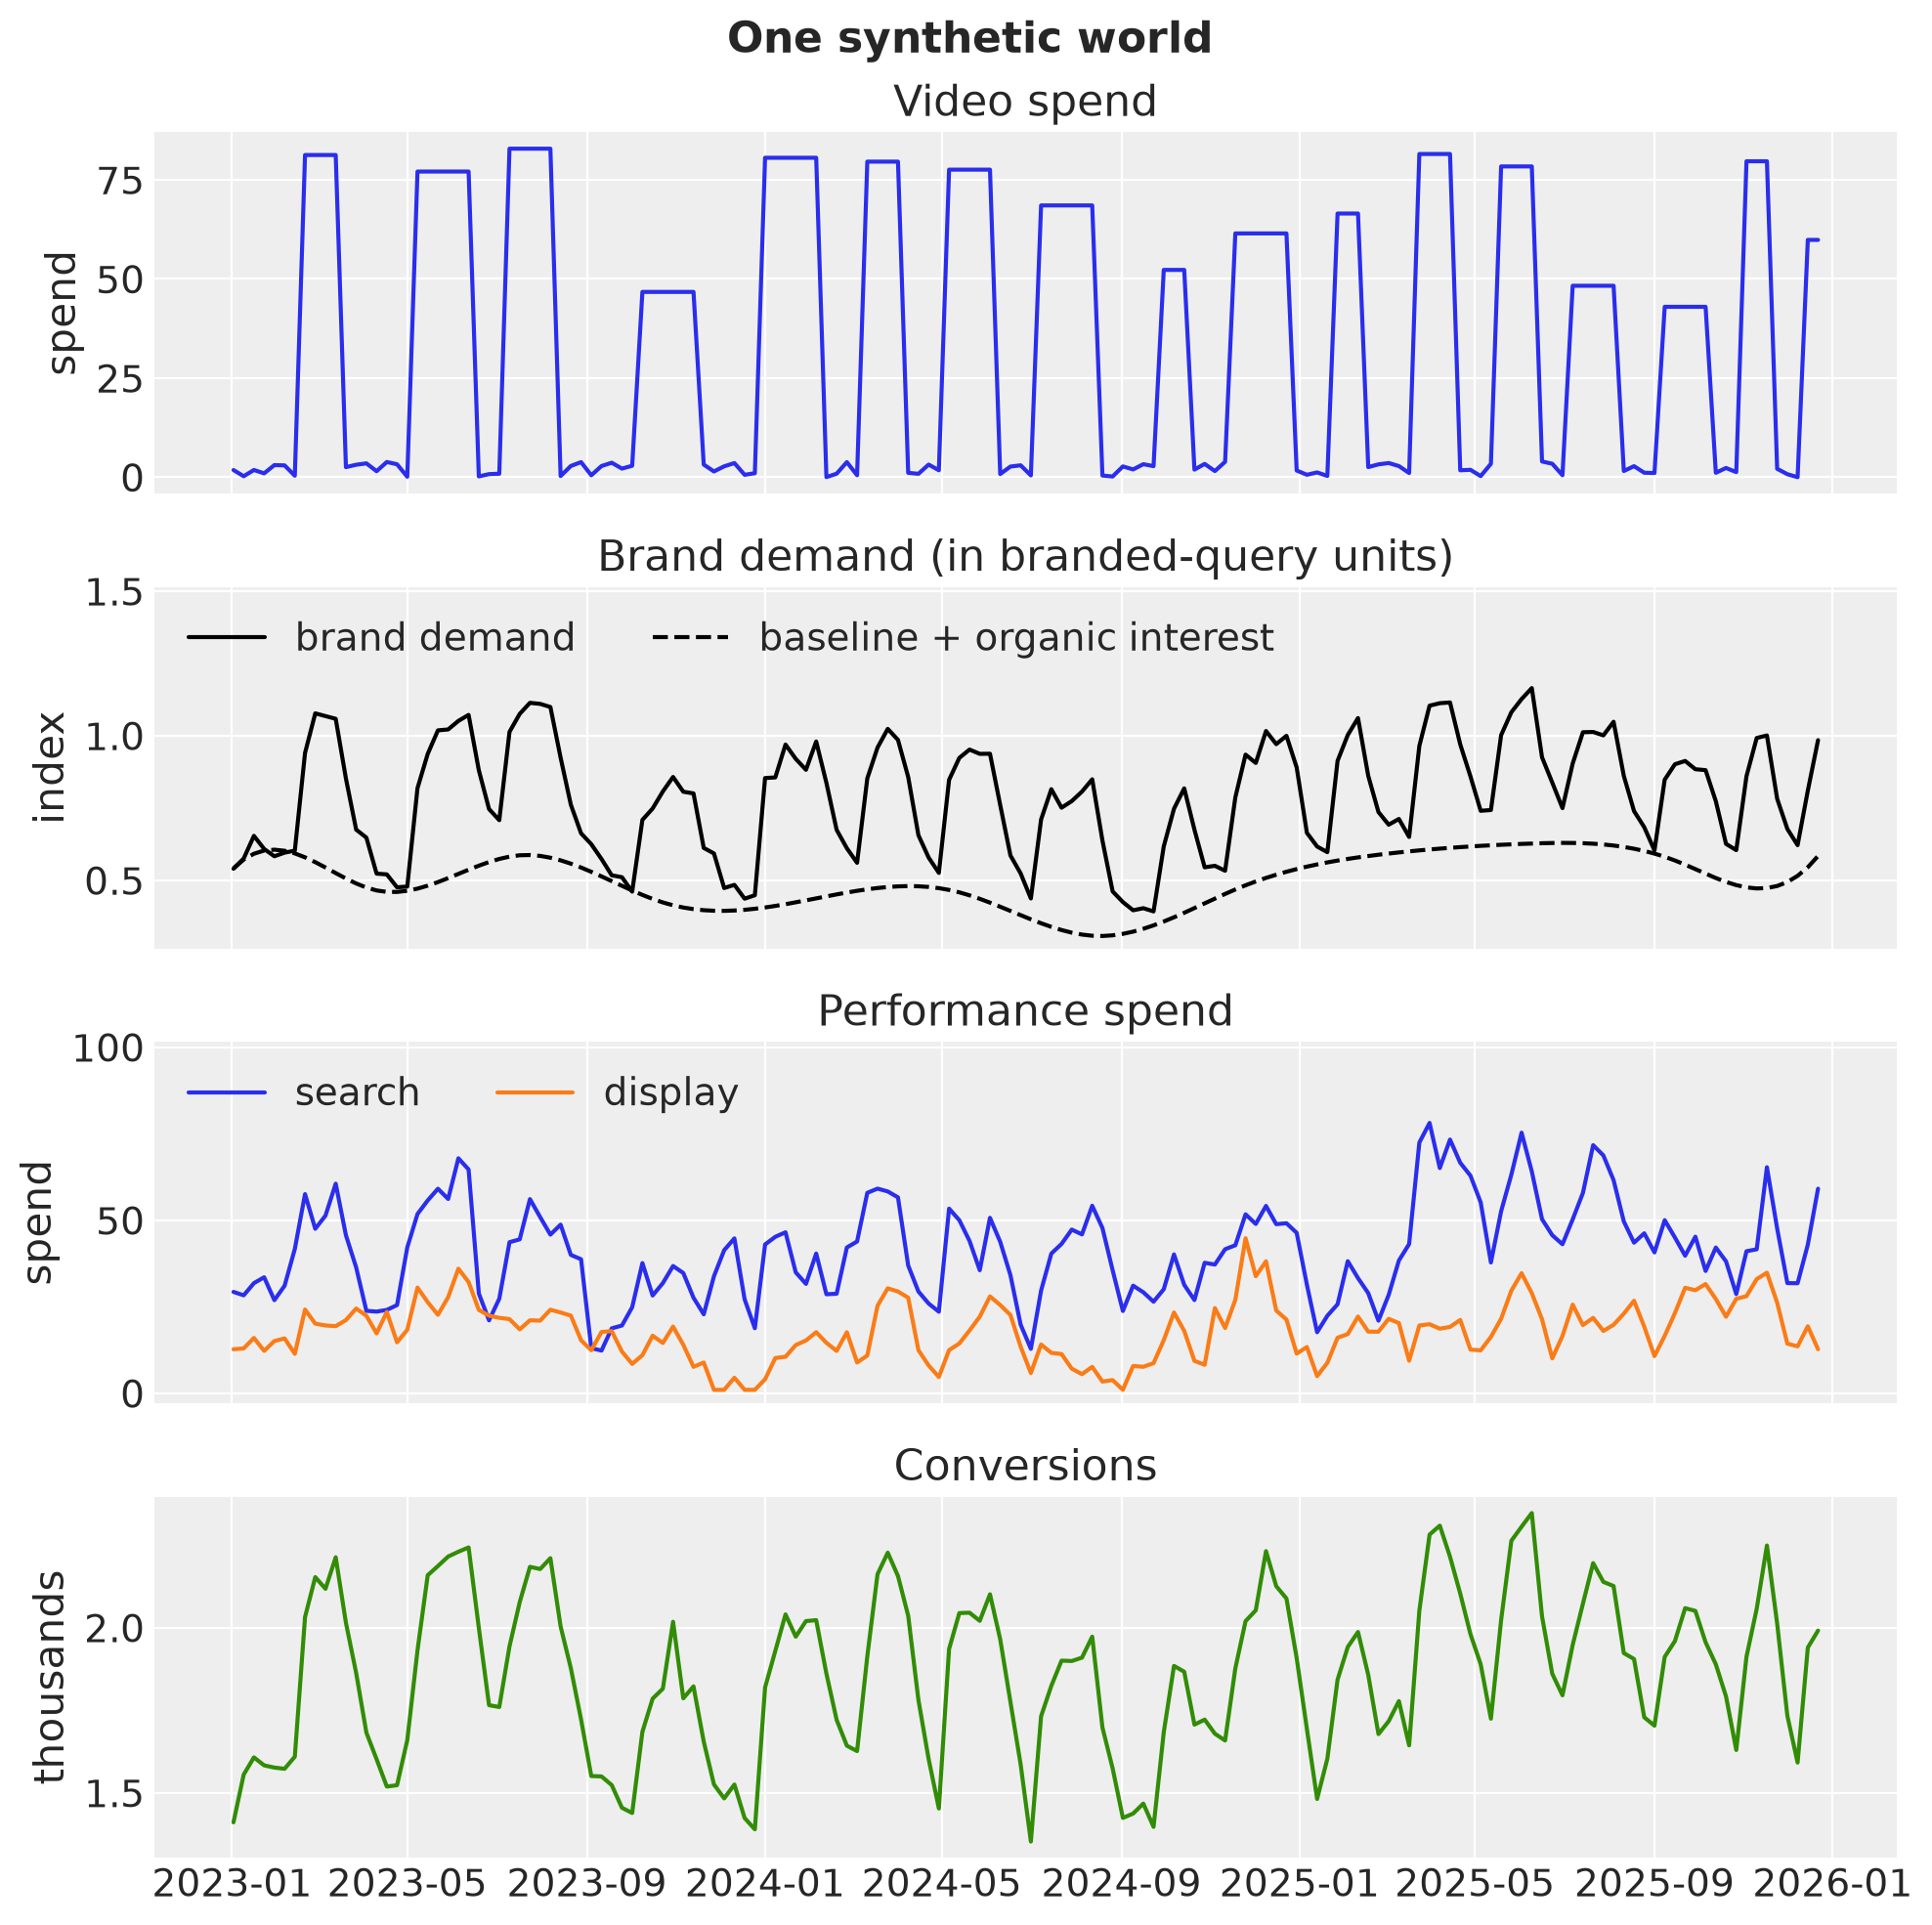

In [8]:
world, truth = simulate_world(rng)
basis = spline_basis()

fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
axes[0].plot(world["date"], world["video"], color="C0")
axes[0].set(title="Video spend", ylabel="spend")
axes[1].plot(world["date"], world["demand_true"], color="black", label="brand demand")
axes[1].plot(
    world["date"],
    true["query_baseline"] + world["organic_true"],
    color="black",
    linestyle="--",
    label="baseline + organic interest",
)
axes[1].set(
    title="Brand demand (in branded-query units)",
    ylabel="index",
    ylim=(None, 1.3 * world["demand_true"].max()),
)
axes[1].legend(loc="upper left", ncol=2)
axes[2].plot(world["date"], world["search"], label="search")
axes[2].plot(world["date"], world["display"], label="display")
axes[2].set(
    title="Performance spend",
    ylabel="spend",
    ylim=(None, 1.3 * world["search"].max()),
)
axes[2].legend(loc="upper left", ncol=2)
axes[3].plot(world["date"], world["conversions"], color="C2")
axes[3].set(title="Conversions", ylabel="thousands")
fig.suptitle("One synthetic world", fontsize=16, fontweight="bold")
fig.tight_layout();

**Caption:** One simulated world. Each video flight lifts brand demand above its organic level (dashed). Search and display spend follow demand, plus budget changes of their own.

In [9]:
mean_conversions = world["conversions"].mean()
pd.DataFrame(
    {
        "mean weekly contribution": {k: v.mean() for k, v in truth.items()},
        "share of conversions": {
            k: v.mean() / mean_conversions for k, v in truth.items()
        },
    }
).style.format({"mean weekly contribution": "{:.3f}", "share of conversions": "{:.1%}"})

,mean weekly contribution,share of conversions
video_direct,0.118,6.3%
video_indirect,0.145,7.8%
video_total,0.262,14.1%
search,0.214,11.5%
display,0.134,7.2%


Video drives about 14% of conversions, and 55% of that goes through brand demand. Search and display drive about 12% and 7%. The rest comes from the intercept.

## Models

Three building blocks make up every model in the notebook.

The demand equation is shared by stage 1 and the joint model: a baseline, video's lift through adstock and logistic saturation, and organic interest as a cubic spline with 12 basis functions (a smooth curve whose shape is estimated). Branded queries measure demand with normal noise. Demand is expressed in branded-query units, which fixes its scale.

Stage 1 has no conversions, so it is a small PyMC model rather than an MMM. It scales video spend the same way the MMM does, dividing by its maximum.

In [10]:
sample_kwargs = {"chains": 4, "tune": 1_000, "draws": 1_000, "target_accept": 0.9}


def hub_transforms():
    """Adstock and saturation for video -> branded query volume."""
    return {
        "hub_adstock": GeometricAdstock(l_max=L_MAX, prefix="adstock_hub"),
        "hub_saturation": LogisticSaturation(prefix="sat_hub"),
    }


def query_equation(video_scaled, basis, hub_adstock, hub_saturation):
    """Build the query equation: baseline + video lift + smooth organic interest."""
    lift = pmd.Deterministic(
        "query_lift",
        hub_saturation.apply(
            hub_adstock.apply(video_scaled, core_dim="date"), core_dim="date"
        ),
    )
    baseline = pmd.HalfNormal("query_baseline", sigma=1.0)
    organic_sigma = pmd.HalfNormal("query_organic_sigma", sigma=0.5)
    organic_z = pmd.Normal("query_organic_z", 0.0, 1.0, dims="knot")
    basis_data = pmd.Data("query_basis", basis, dims=("date", "knot"))
    organic = pmd.dot(basis_data, organic_sigma * organic_z, dim="knot")
    return pmd.Deterministic("query_latent", baseline + lift + organic)


def query_likelihood(latent, observed):
    """Attach the likelihood of observed query volume."""
    pmd.Normal(
        "query_measurement",
        mu=latent,
        sigma=pmd.HalfNormal("query_noise", sigma=0.5),
        observed=observed,
    )


def fit_stage1(frame, basis, **kwargs):
    """Stage 1: fit the query equation on observed query volume alone."""
    coords = {"date": frame["date"].to_numpy(), "knot": np.arange(basis.shape[1])}
    with pm.Model(coords=coords):
        # Same scaling as the MMM: spend divided by its maximum.
        video = pmd.Data(
            "video_scaled", frame["video"] / frame["video"].max(), dims="date"
        )
        latent = query_equation(video, basis, **hub_transforms())
        observed = pmd.Data(
            "branded_queries", frame["branded_queries"].to_numpy(), dims="date"
        )
        query_likelihood(latent, observed)
        return pm.sample(
            nuts_sampler="nutpie",
            progressbar=False,
            random_seed=rng,
            **{**sample_kwargs, **kwargs},
        )

The sales equation is an `MMM` with the three channels, plus a custom {class}`~pymc_marketing.mmm.additive_effect.MuEffect` for the demand path. As in the data, the demand path is linear after adstock: twice the demand brings twice the conversions from that path.

- `QuerySeriesEffect` is stage 2. It takes a demand series from the dataset, either the observed branded queries or stage 1's estimate of demand, and has no likelihood of its own.
- `JointQueryEffect` is the joint model. It builds the demand equation inside the MMM, attaches the branded-query likelihood, and passes either the model's demand or the observed branded queries to the sales equation.

In [11]:
class QuerySeriesEffect(DataVarMuEffect):
    """Stage 2: a given query series enters conversions through adstock and a coefficient."""

    prefix: str = "query"

    def to_dict(self) -> dict:
        """Serialize the effect."""
        return {"prefix": self.prefix, "data_vars": list(self.data_vars)}

    def create_effect(self, mmm):
        """Return the contribution of the query series to conversions."""
        series = mmm.model[self.data_vars[0]]
        adstocked = GeometricAdstock(l_max=L_MAX, prefix="adstock_query").apply(
            series, core_dim="date"
        )
        coef = pmd.HalfNormal("query_coef", sigma=1.0)
        return pmd.Deterministic("query_effect_contribution", coef * adstocked)


class JointQueryEffect(DataVarMuEffect):
    """Joint model: the query equation with its own likelihood, and its path to conversions.

    ``sales_input="latent"`` passes the model's query volume to conversions;
    ``sales_input="observed"`` passes the observed series.
    """

    prefix: str = "query"
    basis: InstanceOf[np.ndarray]
    sales_input: str = "latent"
    hub_adstock: InstanceOf[AdstockTransformation]
    hub_saturation: InstanceOf[SaturationTransformation]

    def to_dict(self) -> dict:
        """Serialize the effect."""
        return {"prefix": self.prefix, "data_vars": list(self.data_vars)}

    def create_data(self, mmm) -> None:
        """Register the observed series and the spline coordinate."""
        mmm.model.add_coord("knot", np.arange(self.basis.shape[1]))
        super().create_data(mmm)

    def create_effect(self, mmm):
        """Build the query equation and return its contribution to conversions."""
        latent = query_equation(
            mmm.scaled_channel("video"),
            self.basis,
            self.hub_adstock,
            self.hub_saturation,
        )
        observed = mmm.model[self.data_vars[0]]
        query_likelihood(latent, observed)
        series = latent if self.sales_input == "latent" else observed
        adstocked = GeometricAdstock(l_max=L_MAX, prefix="adstock_query").apply(
            series, core_dim="date"
        )
        coef = pmd.HalfNormal("query_coef", sigma=1.0)
        return pmd.Deterministic("query_effect_contribution", coef * adstocked)

In [12]:
def make_mmm():
    """MMM with the three channels."""
    return MMM(
        date_column="date",
        target_column="conversions",
        channel_columns=CHANNELS,
        adstock=GeometricAdstock(l_max=L_MAX),
        saturation=LogisticSaturation(),
        sampler_config={"nuts_sampler": "nutpie"},
    )


def fit_mmm(mmm, frame, extra_vars, **kwargs):
    """Build the model from a dataset that carries ``extra_vars``, then fit it."""
    X = to_mmm_dataset(
        frame.drop(columns="conversions"),
        date_column="date",
        channel_columns=CHANNELS,
        extra_vars=extra_vars,
    )
    mmm.build_model(X, frame["conversions"])
    mmm.add_original_scale_contribution_variable(var=["channel_contribution"])
    mmm.fit(
        frame[["date", *CHANNELS]],
        frame["conversions"],
        progressbar=False,
        random_seed=rng,
        **{**sample_kwargs, **kwargs},
    )
    return mmm


def fit_stage2(frame, series_col, **kwargs):
    """Stage 2: fit the sales equation with a given query series as an input."""
    mmm = make_mmm()
    mmm.add_mu_effect(QuerySeriesEffect(data_vars=[series_col]))
    return fit_mmm(mmm, frame, [series_col], **kwargs)


def fit_joint(frame, basis, sales_input="latent", **kwargs):
    """Fit the query and sales equations together."""
    mmm = make_mmm()
    mmm.add_mu_effect(
        JointQueryEffect(
            data_vars=["branded_queries"],
            basis=basis,
            sales_input=sales_input,
            **hub_transforms(),
        )
    )
    return fit_mmm(mmm, frame, ["branded_queries"], **kwargs)

The same function computes every model's effects. Video's direct effect is its channel contribution. Its effect through demand is the coefficient of demand times the adstocked lift that video adds to demand. All effects hold the other channels' spend at its observed level. We compare each model's mean weekly effect with the true value and report 94% intervals.

In [13]:
PATHS = ["video_direct", "video_indirect", "video_total", "search", "display"]
PATH_LABELS = {
    "video_direct": "Video, direct",
    "video_indirect": "Video, through demand",
    "video_total": "Video, total",
    "search": "Search",
    "display": "Display",
}


def flat(idata, var):
    """Posterior draws of ``var`` with a leading ``sample`` axis."""
    da = idata.posterior[var].stack(sample=("chain", "draw"))
    return da.transpose("sample", ...).to_numpy()


def path_effects(idata, lift):
    """Weekly effect of each path per posterior draw, in conversions.

    ``lift`` holds the draws of video's lift on query volume. For two-stage fits it
    comes from stage 1 and is paired draw by draw with the stage-2 draws.
    """
    target_scale = float(idata.constant_data["target_scale"].squeeze())
    contrib = idata.posterior["channel_contribution_original_scale"]
    channel = {
        c: contrib.sel(channel=c).stack(sample=("chain", "draw")).transpose().to_numpy()
        for c in CHANNELS
    }
    indirect = (
        flat(idata, "query_coef")[:, None]
        * adstock(lift, flat(idata, "adstock_query_alpha"))
        * target_scale
    )
    return {
        "video_direct": channel["video"],
        "video_indirect": indirect,
        "video_total": channel["video"] + indirect,
        "search": channel["search"],
        "display": channel["display"],
    }


def summarize(model_effects, truth, prob=0.94):
    """Mean-over-time effect per model and path, relative to the truth."""
    tail = (1 - prob) / 2
    rows = []
    for model, paths in model_effects.items():
        for path in PATHS:
            estimate = paths[path].mean(axis=1)
            true_value = truth[path].mean()
            lower, upper = np.quantile(estimate, [tail, 1 - tail])
            rows.append(
                {
                    "model": model,
                    "path": path,
                    "truth": true_value,
                    "mean": estimate.mean(),
                    "lower": lower,
                    "upper": upper,
                    "bias": estimate.mean() / true_value - 1,
                    "width": (upper - lower) / true_value,
                    "covers": lower <= true_value <= upper,
                }
            )
    return pd.DataFrame(rows)


def diagnostics(fits):
    """Divergences, worst r-hat, and lowest bulk ESS per fit (scalar parameters only)."""
    rows = {}
    for name, idata in fits.items():
        params = [
            v
            for v, da in idata.posterior.data_vars.items()
            if not {"date", "knot"} & set(da.dims)
        ]
        summary = az.summary(idata, var_names=params)
        rows[name] = {
            "divergences": int(idata["sample_stats"]["diverging"].sum()),
            "max r_hat": float(summary["r_hat"].max()),
            "min ess_bulk": float(summary["ess_bulk"].min()),
        }
    return pd.DataFrame(rows).T

In [14]:
MODEL_COLORS = {
    "Two-stage, observed queries": "#2a78d6",
    "Two-stage, estimated demand": "#eb6834",
    "Two-stage, multiple imputation": "#a35dd1",
    "Joint": "#1baf7a",
}


def plot_recovery(summaries, title):
    """Forest plot of each estimate relative to the truth: rows are settings, columns paths."""
    fig, axes = plt.subplots(
        nrows=len(summaries),
        ncols=len(PATHS),
        figsize=(14, 1.2 + 1.6 * len(summaries)),
        sharex="col",
        squeeze=False,
    )
    for i, (setting, table) in enumerate(summaries.items()):
        models = list(dict.fromkeys(table["model"]))
        table = table.set_index(["model", "path"])
        for j, path in enumerate(PATHS):
            ax = axes[i, j]
            for k, model in enumerate(models):
                row = table.loc[(model, path)]
                rel = (
                    np.array([row["lower"], row["mean"], row["upper"]]) / row["truth"]
                    - 1
                )
                color = MODEL_COLORS[model]
                ax.plot(rel[[0, 2]] * 100, [k, k], color=color, linewidth=2)
                ax.plot(rel[1] * 100, k, "o", color=color, markersize=7, label=model)
            ax.axvline(0, color="black", linestyle="--", linewidth=1.2)
            ax.set(yticks=[], ylim=(-0.7, len(models) - 0.3))
            if i == 0:
                ax.set_title(PATH_LABELS[path])
            if j == 0:
                ax.set_ylabel(setting)
            if i == len(summaries) - 1:
                ax.set_xlabel("vs. truth (%)")
    handles, labels = [], []
    for ax in axes.flat:
        for h, lab in zip(*ax.get_legend_handles_labels(), strict=True):
            if lab not in labels:
                handles.append(h)
                labels.append(lab)
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=len(labels),
        bbox_to_anchor=(0.5, -0.06),
    )
    fig.suptitle(title, fontsize=16, fontweight="bold")
    fig.tight_layout(rect=(0, 0.02, 1, 1))
    return fig


def format_summary(table):
    """Recovery table: estimate, 94% interval, and error relative to the truth."""
    out = table.assign(path=table["path"].map(PATH_LABELS)).set_index(["path", "model"])
    return out[
        ["truth", "mean", "lower", "upper", "bias", "width", "covers"]
    ].style.format(
        {
            "truth": "{:.3f}",
            "mean": "{:.3f}",
            "lower": "{:.3f}",
            "upper": "{:.3f}",
            "bias": "{:+.0%}",
            "width": "{:.0%}",
        }
    )


z_94 = stats.norm.ppf(0.97)


def coverage_table(replications):
    """Coverage, bias, and typical vs claimed error per path and model."""
    table = (
        replications.assign(path=replications["path"].map(PATH_LABELS))
        .groupby(["path", "model"], sort=False)
        .agg(
            coverage=("covers", "mean"),
            mean_bias=("bias", "mean"),
            typical_error=("bias", lambda b: np.sqrt(np.mean(b**2))),
            claimed_error=("width", lambda w: w.mean() / (2 * z_94)),
        )
    )
    return table.style.format(
        {
            "coverage": "{:.0%}",
            "mean_bias": "{:+.0%}",
            "typical_error": "{:.1%}",
            "claimed_error": "{:.1%}",
        }
    )

We also compute two decision-level measures.

- Cross-stage correlation: the correlation across posterior draws between video's direct effect (sales equation) and video's lift on demand (demand equation). Two stages fit the equations separately, so this is zero by construction. A joint model can learn it from the data, but only when conversions carry information about demand.
- Budget loss: we split the average weekly budget across the three channels, holding spend constant every week, and pick the split with the highest expected conversions under each model. For two-stage models the response chains both stages. We then score that split in the true world: the share of conversions it loses against the true best split. This is the cost, in conversions, of acting on each model.

In [15]:
def media_response(sales, demand, plans, through_demand=True):
    """Compute expected weekly conversions from media per plan (rows) and draw (columns).

    ``sales`` holds the sales-equation draws and ``demand`` the demand-equation
    draws: stage 2 and stage 1 for a two-stage fit, the same posterior for a joint
    fit. Spend is constant every week, so the normalized adstock leaves it unchanged.
    """
    target_scale = float(sales.constant_data["target_scale"].squeeze())
    scale = sales.constant_data["channel_scale"].sel(channel=CHANNELS).to_numpy()
    lam = flat(sales, "saturation_lam").T
    beta = flat(sales, "saturation_beta").T
    response = sum(
        beta[c] * saturate(plans[:, [c]] / scale[c], lam[c])
        for c in range(len(CHANNELS))
    )
    if through_demand:
        lift = flat(demand, "sat_hub_beta") * saturate(
            plans[:, [0]] / scale[0], flat(demand, "sat_hub_lam")
        )
        response = response + flat(sales, "query_coef") * lift
    return response * target_scale


def true_media_response(plans, world):
    """Compute the true expected weekly conversions from media for each plan."""
    response = sum(
        true[f"{c}_beta"] * saturate(plans[:, i] / world[c].max(), true[f"{c}_lam"])
        for i, c in enumerate(CHANNELS)
    )
    lift = true["sat_hub_beta"] * saturate(
        plans[:, 0] / world["video"].max(), true["sat_hub_lam"]
    )
    return response + true["query_coef"] * lift


def plan_grid(world, step=0.02):
    """Every split of the average weekly budget across the channels, in steps of 2%."""
    budget = world[CHANNELS].mean().sum()
    shares = np.arange(0, 1 + step / 2, step)
    return budget * np.array(
        [(a, b, 1 - a - b) for a in shares for b in shares if a + b <= 1 + step / 2]
    )


def plan_loss(plan, world):
    """Conversions a plan loses in the true world, relative to the true best plan."""
    best = true_media_response(plan_grid(world), world).max()
    return true_media_response(plan[None, :], world)[0] / best - 1


def best_plan(sales, demand, world, through_demand=True):
    """Find the plan with the highest expected conversions under the model."""
    plans = plan_grid(world)
    response = media_response(sales, demand, plans, through_demand).mean(axis=1)
    return plans[response.argmax()]


def cross_stage_correlation(sales, lift):
    """Correlation across draws between video's direct effect and its lift on demand."""
    direct = (
        sales.posterior["channel_contribution_original_scale"]
        .sel(channel="video")
        .mean("date")
        .stack(sample=("chain", "draw"))
        .to_numpy()
    )
    return float(np.corrcoef(direct, lift.mean(axis=1))[0, 1])


def evaluate(models, world):
    """Effects, cross-stage correlation, and budget plan for fitted models.

    ``models`` maps a label to ``(sales, demand)``, the posteriors of the sales and
    demand equations.
    """
    effects, rows = {}, []
    for label, (sales, demand) in models.items():
        lift = flat(demand, "query_lift")
        effects[label] = path_effects(sales, lift)
        plan = best_plan(sales, demand, world)
        rows.append(
            {
                "model": label,
                "correlation": cross_stage_correlation(sales, lift),
                **{
                    f"{c} share": s
                    for c, s in zip(CHANNELS, plan / plan.sum(), strict=True)
                },
                "budget loss": plan_loss(plan, world),
            }
        )
    return effects, pd.DataFrame(rows).set_index("model")


def format_decisions(table):
    """Cross-stage correlation, budget shares, and conversions lost against the true best plan."""
    formats = {f"{c} share": "{:.0%}" for c in CHANNELS}
    formats.update({"correlation": "{:+.2f}", "budget loss": "{:+.1%}"})
    return table.style.format(formats, na_rep="")


def decision_summary(decisions):
    """Average cross-stage correlation, and average and worst budget loss, per model."""
    table = decisions.groupby("model", sort=False).agg(
        mean_correlation=("correlation", "mean"),
        mean_budget_loss=("budget loss", "mean"),
        worst_budget_loss=("budget loss", "min"),
    )
    return table.style.format(
        {
            "mean_correlation": "{:+.2f}",
            "mean_budget_loss": "{:+.1%}",
            "worst_budget_loss": "{:+.1%}",
        }
    )

## Layer 1: branded queries measure demand exactly

We start where theory says the two strategies agree. Branded queries measure demand without error, so the sales equation can use them directly. The joint model here also passes the observed series to the sales equation (`sales_input="observed"`), so both strategies share the same specification.

In [16]:
frame_exact = measure_queries(world, sigma=0.0, rng=rng)

stage1_exact = fit_stage1(frame_exact, basis)
stage2_exact = fit_stage2(frame_exact, "branded_queries")
joint_exact = fit_joint(frame_exact, basis, sales_input="observed")

diagnostics(
    {
        "stage 1": stage1_exact,
        "stage 2": stage2_exact.idata,
        "joint": joint_exact.idata,
    }
)

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_organic_sigma, query_organic_z, query_noise]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, query_organic_z, query_organic_sigma, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, y_sigma, query_noise]


,divergences,max r_hat,min ess_bulk
stage 1,0.0,1.01,430.0
stage 2,0.0,1.01,504.0
joint,0.0,1.00,790.0


In [17]:
effects_exact, decisions_exact = evaluate(
    {
        "Two-stage, observed queries": (stage2_exact.idata, stage1_exact),
        "Joint": (joint_exact.idata, joint_exact.idata),
    },
    world,
)
summary_exact = summarize(effects_exact, truth)
format_summary(summary_exact)

,,truth,mean,lower,upper,bias,width,covers
path,model,,,,,,,
"Video, direct","Two-stage, observed queries",0.118,0.116,0.090,0.143,-1%,45%,True
"Video, through demand","Two-stage, observed queries",0.145,0.132,0.107,0.160,-8%,37%,True
"Video, total","Two-stage, observed queries",0.262,0.249,0.229,0.269,-5%,15%,True
Search,"Two-stage, observed queries",0.214,0.237,0.195,0.292,+11%,45%,True
Display,"Two-stage, observed queries",0.134,0.132,0.104,0.163,-1%,44%,True
"Video, direct",Joint,0.118,0.116,0.091,0.143,-1%,44%,True
"Video, through demand",Joint,0.145,0.132,0.106,0.158,-8%,36%,True
"Video, total",Joint,0.262,0.249,0.229,0.269,-5%,15%,True
Search,Joint,0.214,0.237,0.194,0.292,+11%,46%,True


The decision table adds three reference rows: the plan an optimizer finds when it sees stage 2 only, with demand held where it is; the historical mix of spend; and the true best plan. (The library's own {class}`~pymc_marketing.mmm.budget_optimizer.BudgetOptimizer`, used in {ref}`mmm_budget_allocation_example`, would replace the grid search below in a real analysis; we use a grid here to keep the mechanics visible.)

In [18]:
references = {
    "Two-stage, stage 2 only": best_plan(
        stage2_exact.idata, stage1_exact, world, through_demand=False
    ),
    "Historical mix": world[CHANNELS].mean().to_numpy(),
    "True best plan": plan_grid(world)[
        true_media_response(plan_grid(world), world).argmax()
    ],
}
reference_rows = pd.DataFrame(
    [
        {
            "model": label,
            **{
                f"{c} share": s
                for c, s in zip(CHANNELS, plan / plan.sum(), strict=True)
            },
            "budget loss": plan_loss(plan, world),
        }
        for label, plan in references.items()
    ]
).set_index("model")
format_decisions(pd.concat([decisions_exact, reference_rows]))

,correlation,video share,search share,display share,budget loss
model,,,,,
"Two-stage, observed queries",+0.01,46%,34%,20%,-0.9%
Joint,+0.01,46%,34%,20%,-0.9%
"Two-stage, stage 2 only",,0%,76%,24%,-28.0%
Historical mix,,37%,44%,19%,-3.1%
True best plan,,50%,24%,26%,+0.0%


The two fits agree. Their effects match to three decimals, they recommend the same budget split, and both lose 0.9% of conversions against the true best split. That loss comes from ordinary estimation error, such as search being 11% too high in both fits. The cross-stage correlation is about zero in both (+0.01), as the factorization predicts: with exact queries, the joint model has nothing to learn across the two equations.

The reference rows show why the optimizer must see both stages. With stage 2 only, it treats demand as fixed, so video looks worthless: it gets 0% of the budget, and the plan loses 28% of the achievable conversions, far more than the historical mix (3.1%). A joint model has the chain from video to demand to conversions built in. With two stages, the chain has to be added by hand, as every two-stage row in this notebook does.

## Layer 2: branded queries measure demand with noise

Now branded queries are demand plus noise with a standard deviation of 0.1, on an index that averages about 0.7. How much this matters depends on how the noise compares with the part of demand that video does not explain.

In [19]:
query_noise = 0.1
other_variation = np.var(
    world["demand_true"]
    - true["sat_hub_beta"]
    * saturate(
        adstock(world["video"] / world["video"].max(), true["adstock_hub_alpha"])[0],
        true["sat_hub_lam"],
    )
)
print(
    "Share of the demand variation not driven by video that the queries capture: "
    f"{other_variation / (other_variation + query_noise**2):.0%}"
)

Share of the demand variation not driven by video that the queries capture: 45%


With noisy queries, there are three ways to run two stages: use the observed series in stage 2 as if it were demand; use stage 1's estimate of demand, its posterior mean; or refit stage 2 on 20 demand series drawn from stage 1's posterior and pool the draws (multiple imputation), which carries stage 1's uncertainty about demand into stage 2 at 20 times the cost. This last option is only fit on this one world, and only for the effects.

The joint model treats demand as unknown in both equations. Estimated demand, multiple imputation, and the joint model share the same specification. Observed queries does not: it assumes the noisy series is what drives conversions.

In [20]:
def fit_multiple_imputation(frame, stage1, n_imputations=20, **kwargs):
    """Refit stage 2 on demand series drawn from stage 1 and pool the results."""
    latent = flat(stage1, "query_latent")
    lift = flat(stage1, "query_lift")
    pooled = []
    for k in rng.choice(latent.shape[0], n_imputations, replace=False):
        mmm = fit_stage2(frame.assign(queries_draw=latent[k]), "queries_draw", **kwargs)
        pooled.append(path_effects(mmm.idata, lift[k][None, :]))
    return {path: np.concatenate([p[path] for p in pooled]) for path in PATHS}


frame_noisy = measure_queries(world, sigma=query_noise, rng=rng)
stage1_noisy = fit_stage1(frame_noisy, basis)
frame_noisy = frame_noisy.assign(
    queries_estimated=flat(stage1_noisy, "query_latent").mean(axis=0)
)
observed_noisy = fit_stage2(frame_noisy, "branded_queries")
estimated_noisy = fit_stage2(frame_noisy, "queries_estimated")
imputed_noisy = fit_multiple_imputation(
    frame_noisy, stage1_noisy, chains=2, tune=500, draws=500
)
joint_noisy = fit_joint(frame_noisy, basis)

diagnostics(
    {
        "stage 1": stage1_noisy,
        "stage 2, observed queries": observed_noisy.idata,
        "stage 2, estimated demand": estimated_noisy.idata,
        "joint": joint_noisy.idata,
    }
)

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_organic_sigma, query_organic_z, query_noise]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


...

NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_organic_z, query_organic_sigma, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_coef, intercept_contribution, y_sigma, query_noise]


,divergences,max r_hat,min ess_bulk
stage 1,0.0,1.01,400.0
"stage 2, observed queries",0.0,1.01,341.0
"stage 2, estimated demand",0.0,1.01,432.0
joint,0.0,1.01,765.0


/var/folders/k2/hd2rrq590r9cmwy8cymlr5xw0000gq/T/ipykernel_68191/2265524950.py:54: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0.02, 1, 1))


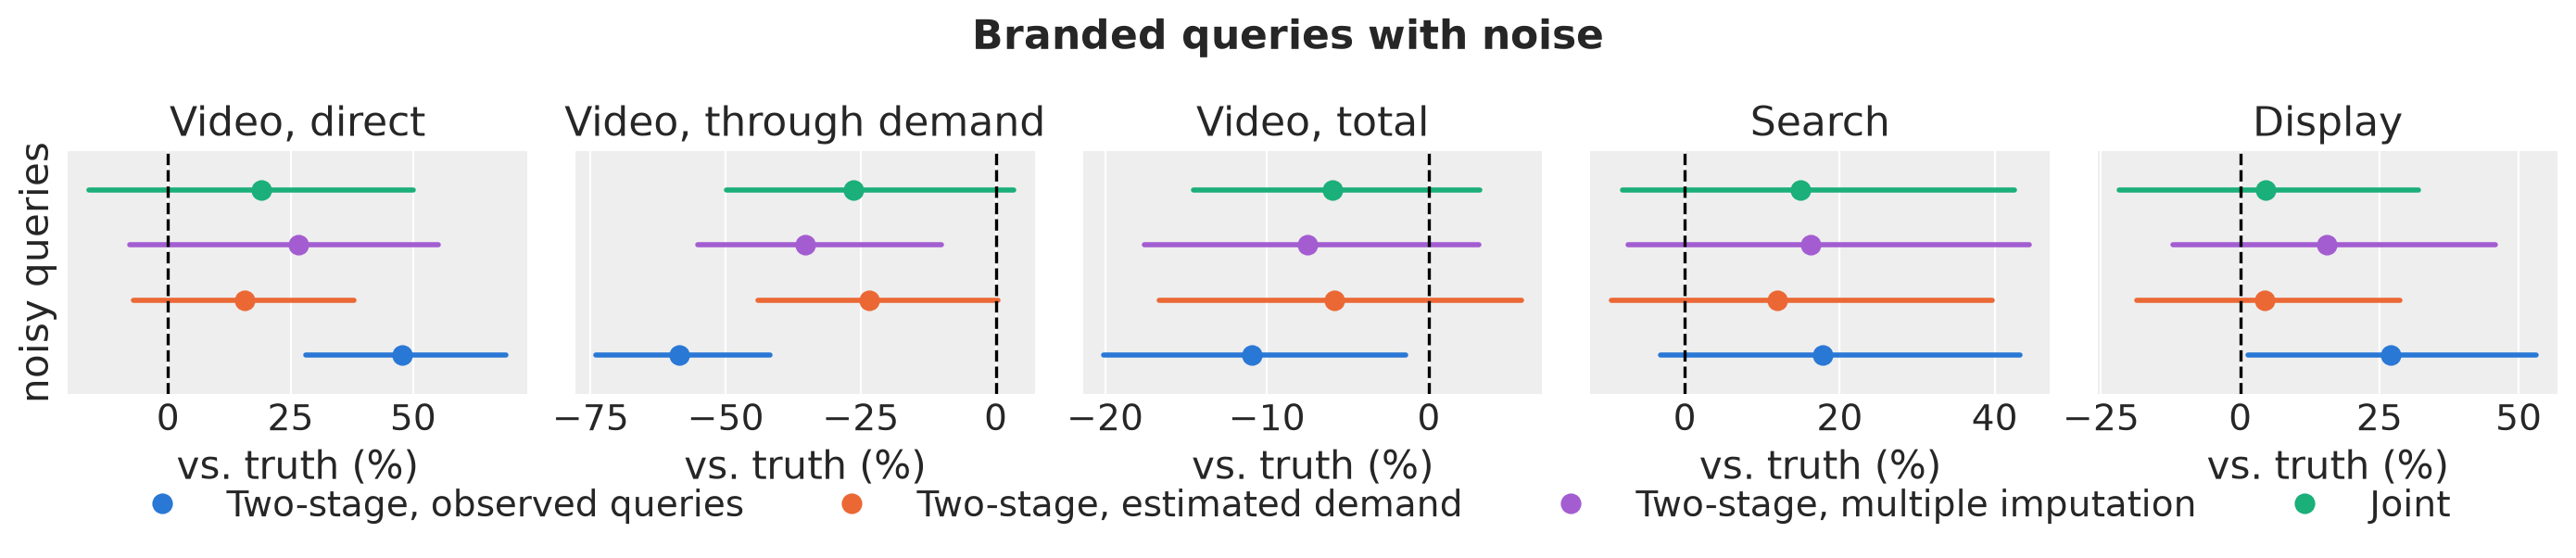

In [21]:
effects_noisy, decisions_noisy = evaluate(
    {
        "Two-stage, observed queries": (observed_noisy.idata, stage1_noisy),
        "Two-stage, estimated demand": (estimated_noisy.idata, stage1_noisy),
        "Joint": (joint_noisy.idata, joint_noisy.idata),
    },
    world,
)
effects_noisy = {
    **{k: v for k, v in effects_noisy.items() if k != "Joint"},
    "Two-stage, multiple imputation": imputed_noisy,
    "Joint": effects_noisy["Joint"],
}
summary_noisy = summarize(effects_noisy, truth)
plot_recovery({"noisy queries": summary_noisy}, "Branded queries with noise");

**Caption:** Each model's estimate relative to the truth (dashed line at 0%). Dots are posterior means; bars are 94% intervals.

In [22]:
format_summary(summary_noisy)

,,truth,mean,lower,upper,bias,width,covers
path,model,,,,,,,
"Video, direct","Two-stage, observed queries",0.118,0.174,0.151,0.199,+48%,41%,False
"Video, through demand","Two-stage, observed queries",0.145,0.060,0.038,0.084,-59%,32%,False
"Video, total","Two-stage, observed queries",0.262,0.233,0.209,0.258,-11%,19%,False
Search,"Two-stage, observed queries",0.214,0.251,0.207,0.306,+18%,46%,True
Display,"Two-stage, observed queries",0.134,0.170,0.135,0.205,+27%,52%,False
"Video, direct","Two-stage, estimated demand",0.118,0.136,0.109,0.162,+16%,45%,True
"Video, through demand","Two-stage, estimated demand",0.145,0.111,0.081,0.145,-23%,44%,True
"Video, total","Two-stage, estimated demand",0.262,0.247,0.218,0.277,-6%,22%,True
Search,"Two-stage, estimated demand",0.214,0.239,0.193,0.298,+12%,49%,True


In [23]:
format_decisions(decisions_noisy)

,correlation,video share,search share,display share,budget loss
model,,,,,
"Two-stage, observed queries",+0.00,42%,38%,20%,-1.5%
"Two-stage, estimated demand",-0.02,48%,34%,18%,-1.1%
Joint,-0.48,46%,36%,18%,-1.3%


Observed queries shows the errors-in-variables pattern: noise in a regressor pulls its estimated effect toward zero. The model understates video's effect through demand by 59% and hands the difference to the direct effect (+48%), and neither interval contains the truth. It over-credits search and display by 18% and 27%, because a noisy series is a weak control for the demand those channels follow. Even the total is 11% low, with an interval that misses the truth.

The three models that estimate demand also understate video's effect through demand, by 23% to 35%, but their intervals mostly contain the truth. The estimated-demand interval (44% of the truth wide) and the joint interval (53%) cover it, while multiple imputation's (45%) misses it. One world cannot separate them; the replications below do.

The joint model's cross-stage correlation is −0.48: in draws where video lifts demand more, its direct effect is smaller. Conversions pin down the sum of the two, and the joint model has learned how they trade off. In the two-stage models the correlation is zero by construction.

On the budget, the three models lose between 1.1% and 1.5% of conversions, with the joint model in the middle (1.3%).

### Replications

One world shows whether an interval happened to contain the truth, not how often it does. We repeat the comparison in 20 new worlds. Across them, the first table reports coverage (the share of 94% intervals that contain the true effect), mean bias (the average error, relative to the truth), typical error (how far the estimate usually lands from the truth), and claimed error (the error the model's own interval implies). When typical and claimed error match, the interval is calibrated; a claimed error below the typical error means the model is overconfident. With 20 worlds, each coverage figure has a simulation error of about ±5 percentage points. The second table reports the cross-stage correlation and the budget loss, on average and in the worst world.

In [24]:
n_reps = 20
fast = {"tune": 1_000, "draws": 500}


def replicate_noisy():
    """One replication of the noisy-query comparison in a new synthetic world."""
    world_r, truth_r = simulate_world(rng)
    frame = measure_queries(world_r, sigma=query_noise, rng=rng)
    stage1 = fit_stage1(frame, basis, **fast)
    frame = frame.assign(queries_estimated=flat(stage1, "query_latent").mean(axis=0))
    observed = fit_stage2(frame, "branded_queries", **fast)
    estimated = fit_stage2(frame, "queries_estimated", **fast)
    joint = fit_joint(frame, basis, **fast)
    effects, decisions = evaluate(
        {
            "Two-stage, observed queries": (observed.idata, stage1),
            "Two-stage, estimated demand": (estimated.idata, stage1),
            "Joint": (joint.idata, joint.idata),
        },
        world_r,
    )
    return summarize(effects, truth_r), decisions.reset_index()


results_noisy = [replicate_noisy() for _ in range(n_reps)]
replications_noisy = pd.concat(
    [summary.assign(rep=r) for r, (summary, _) in enumerate(results_noisy)],
    ignore_index=True,
)
decisions_noisy_reps = pd.concat(
    [decisions.assign(rep=r) for r, (_, decisions) in enumerate(results_noisy)],
    ignore_index=True,
)
coverage_table(replications_noisy)

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_organic_sigma, query_organic_z, query_noise]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_organic_z, query_organic_sigma, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_coef, intercept_contribution, y_sigma, query_noise]


NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_organic_sigma, query_organic_z, query_noise]


...

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_organic_sigma, query_organic_z, query_noise]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_organic_z, query_organic_sigma, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_coef, intercept_contribution, y_sigma, query_noise]


,,coverage,mean_bias,typical_error,claimed_error
path,model,,,,
"Video, direct","Two-stage, observed queries",5%,+36%,38.1%,10.8%
"Video, through demand","Two-stage, observed queries",30%,-27%,29.7%,9.4%
"Video, total","Two-stage, observed queries",95%,+1%,5.9%,5.8%
Search,"Two-stage, observed queries",75%,+15%,22.0%,13.8%
Display,"Two-stage, observed queries",85%,+6%,16.5%,13.5%
"Video, direct","Two-stage, estimated demand",80%,-2%,17.7%,11.9%
"Video, through demand","Two-stage, estimated demand",85%,+2%,17.3%,11.9%
"Video, total","Two-stage, estimated demand",100%,+0%,4.3%,6.4%
Search,"Two-stage, estimated demand",90%,+7%,14.8%,12.6%


In [25]:
decision_summary(decisions_noisy_reps)

,mean_correlation,mean_budget_loss,worst_budget_loss
model,,,
"Two-stage, observed queries",+0.01,-1.3%,-5.8%
"Two-stage, estimated demand",+0.00,-1.4%,-5.2%
Joint,-0.37,-1.1%,-3.9%


Using the noisy series as if it were demand fails in every world. Its errors on video's split are systematic (+36% direct, −27% through demand), and its intervals claim about a third of its typical error, so they contain the truth in only 5% and 30% of worlds. It also over-credits search by 15% on average.

Estimating demand removes the bias, in two stages or one. The two strategies are about equally accurate, with typical errors of 17% to 19% on video's split. They differ in what they claim. The two-stage intervals claim about two thirds of the typical error (11.9% against 17.7% for the direct effect) and contain the truth in 80% and 85% of worlds. The joint model's claims are closer to its typical error (17.9% against 18.5% for the direct effect, 14.7% against 18.7% through demand), and its intervals contain the truth in 95% and 90% of worlds. The gap is modest; on the effect through demand it is within the simulation error of 20 worlds.

On video's total, search, and display, the two are equally accurate. Video's total has a typical error of 4.3% for estimated demand and 4.7% for the joint model.

The cross-stage correlation averages −0.37 in the joint model and zero in the others. On the budget, the joint model loses slightly less: 1.1% of conversions on average and 3.9% in the worst world, against 1.4% and 5.2% for estimated demand, and 1.3% and 5.8% for observed queries. These gaps are small, so read them as "no worse" rather than as a clear win.

## Layer 3: the sales equation misses a driver

The joint model's strength, letting conversions inform demand, is also its main risk. If the sales equation misses something, the joint model can explain the gap by moving demand, and the error spreads into the demand equation. Two stages keep stage 1 out of reach of this.

To test it, we add a temporary lift in conversions that no model includes, such as a price change: a bump of 0.15, about 7% of weekly conversions, spread over about 20 weeks. Branded queries carry the same noise as in layer 2. We compare the estimated-demand two-stage model with the joint model.

In [26]:
def add_unmodeled_driver(world, rng, height=0.15, width=10):
    """Add a temporary lift in conversions that no model includes."""
    t = np.arange(N_WEEKS)
    center = rng.uniform(20, N_WEEKS - 20)
    bump = height * np.exp(-0.5 * ((t - center) / width) ** 2)
    return world.assign(conversions=world["conversions"] + bump), center


def fit_unmodeled(frame, basis, world, **kwargs):
    """Fit the estimated-demand two-stage model and the joint model, then evaluate both."""
    stage1 = fit_stage1(frame, basis, **kwargs)
    frame = frame.assign(queries_estimated=flat(stage1, "query_latent").mean(axis=0))
    estimated = fit_stage2(frame, "queries_estimated", **kwargs)
    joint = fit_joint(frame, basis, **kwargs)
    effects, decisions = evaluate(
        {
            "Two-stage, estimated demand": (estimated.idata, stage1),
            "Joint": (joint.idata, joint.idata),
        },
        world,
    )
    fits = {"stage 1": stage1, "stage 2": estimated.idata, "joint": joint.idata}
    return effects, decisions, fits


world_bump, bump_center = add_unmodeled_driver(world, rng)
effects_bump, decisions_bump, fits_bump = fit_unmodeled(
    measure_queries(world_bump, sigma=query_noise, rng=rng), basis, world
)
diagnostics(fits_bump)

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_organic_sigma, query_organic_z, query_noise]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_organic_z, query_organic_sigma, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_coef, intercept_contribution, y_sigma, query_noise]


,divergences,max r_hat,min ess_bulk
stage 1,0.0,1.01,774.0
stage 2,0.0,1.01,475.0
joint,0.0,1.00,663.0


/var/folders/k2/hd2rrq590r9cmwy8cymlr5xw0000gq/T/ipykernel_68191/2265524950.py:54: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0.02, 1, 1))


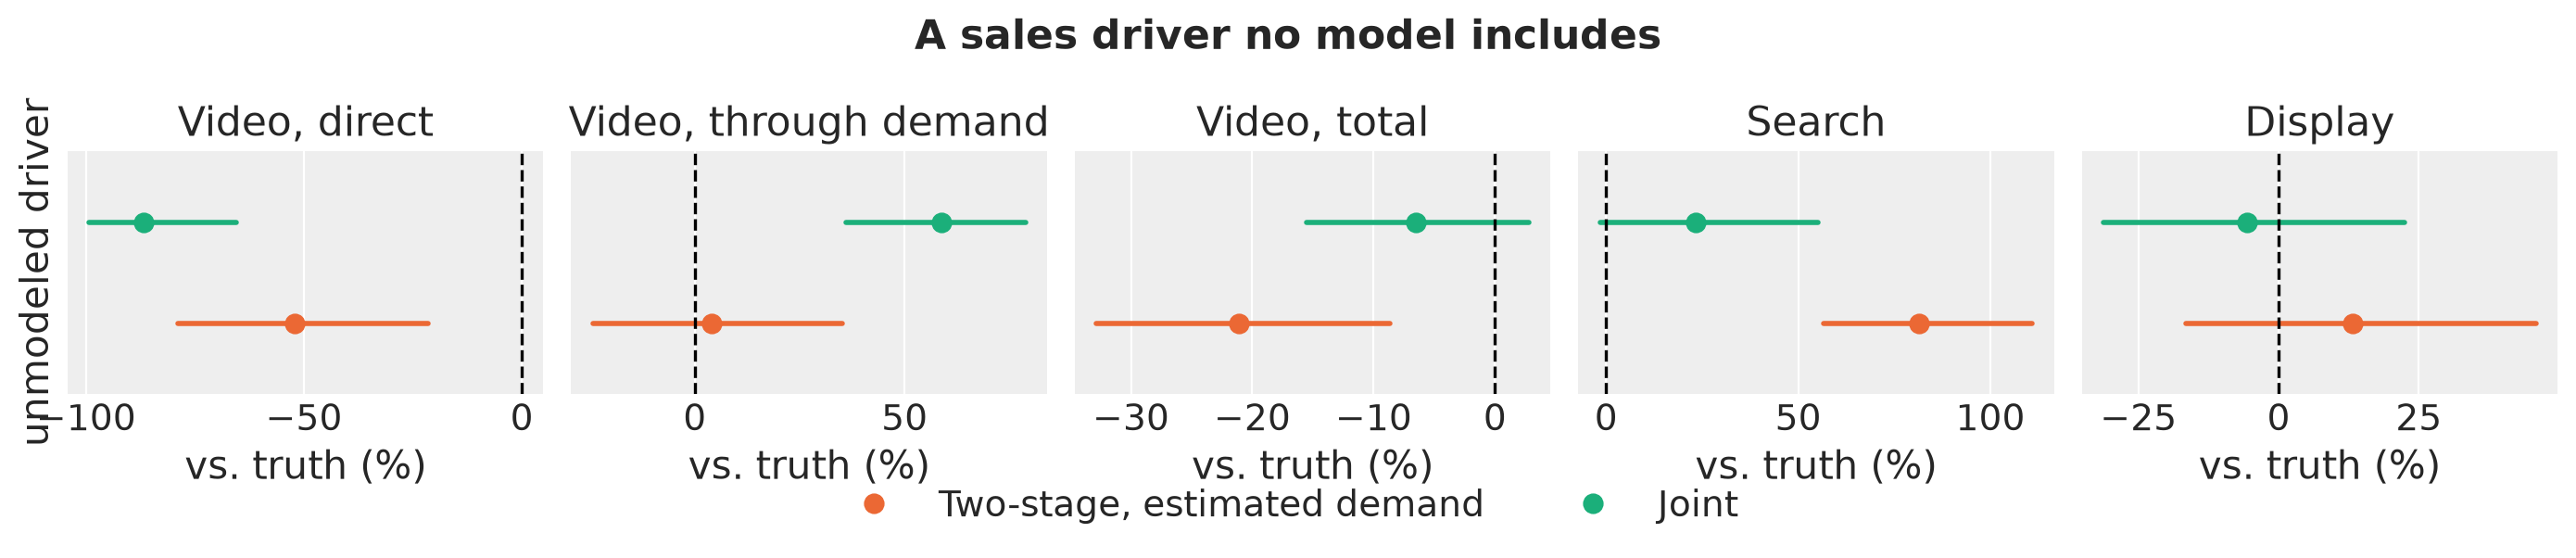

In [27]:
summary_bump = summarize(effects_bump, truth)
plot_recovery({"unmodeled driver": summary_bump}, "A sales driver no model includes");

In [28]:
format_decisions(decisions_bump)

,correlation,video share,search share,display share,budget loss
model,,,,,
"Two-stage, estimated demand",-0.03,16%,70%,14%,-18.1%
Joint,-0.01,40%,44%,16%,-3.2%


In this world, both models miss video's direct effect, and the joint model also misses its effect through demand: it moves credit from the direct path to the path through demand. The two-stage model keeps the effect through demand close to the truth, but it understates video's total by about 21% and over-credits search by about 80%. The joint model's total (about 6% low) and search (about 23% high) are closer. On the budget, the joint model does better: its plan loses 3.2% of conversions, while the two-stage plan, which puts 70% of the budget on search, loses 18.1%.

In [29]:
def replicate_unmodeled():
    """One replication with a new world and a new timing of the unmodeled driver."""
    world_r, truth_r = simulate_world(rng)
    world_bumped, _ = add_unmodeled_driver(world_r, rng)
    effects, decisions, _ = fit_unmodeled(
        measure_queries(world_bumped, sigma=query_noise, rng=rng),
        basis,
        world_r,
        **fast,
    )
    return summarize(effects, truth_r), decisions.reset_index()


results_unmodeled = [replicate_unmodeled() for _ in range(n_reps)]
replications_unmodeled = pd.concat(
    [summary.assign(rep=r) for r, (summary, _) in enumerate(results_unmodeled)],
    ignore_index=True,
)
decisions_unmodeled_reps = pd.concat(
    [decisions.assign(rep=r) for r, (_, decisions) in enumerate(results_unmodeled)],
    ignore_index=True,
)
coverage_table(replications_unmodeled)

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_organic_sigma, query_organic_z, query_noise]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_organic_z, query_organic_sigma, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_coef, intercept_contribution, y_sigma, query_noise]


NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_organic_sigma, query_organic_z, query_noise]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


...

NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_organic_z, query_organic_sigma, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_coef, intercept_contribution, y_sigma, query_noise]


NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_organic_sigma, query_organic_z, query_noise]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_coef, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_query_alpha, query_organic_z, query_organic_sigma, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, query_baseline, query_coef, intercept_contribution, y_sigma, query_noise]


,,coverage,mean_bias,typical_error,claimed_error
path,model,,,,
"Video, direct","Two-stage, estimated demand",55%,+3%,41.0%,15.1%
"Video, through demand","Two-stage, estimated demand",35%,+1%,41.6%,14.5%
"Video, total","Two-stage, estimated demand",70%,+2%,12.1%,7.2%
Search,"Two-stage, estimated demand",75%,+11%,33.3%,16.4%
Display,"Two-stage, estimated demand",70%,+1%,29.8%,15.9%
"Video, direct",Joint,40%,-42%,55.3%,19.2%
"Video, through demand",Joint,20%,+42%,52.2%,16.4%
"Video, total",Joint,70%,+4%,8.2%,5.1%
Search,Joint,90%,-5%,15.4%,13.8%


In [30]:
decision_summary(decisions_unmodeled_reps)

,mean_correlation,mean_budget_loss,worst_budget_loss
model,,,
"Two-stage, estimated demand",-0.00,-4.9%,-27.2%
Joint,-0.24,-1.6%,-7.9%


Across 20 worlds, each with the lift at a different time, the joint model shifts video's credit in the same direction: on average −42% for the direct effect and +42% through demand, with intervals that contain the truth in 40% and 20% of worlds. Its estimate of demand absorbs part of the unexplained lift in conversions, which inflates the path through demand.

The two-stage model has no systematic shift on average (+3% and +1%), but it is scattered. Its typical errors on video's split are 41% and 42%, against claimed errors of about 15%, so its intervals contain the truth in 55% and 35% of worlds. World by world, the joint model's split is less accurate still (typical errors of 55% and 52%).

Everywhere else, the joint model holds up better. On video's total its typical error is 8.2%, against 12.1% for two stages. On search it is 15.4% against 33.3% (the two-stage model over-credits search by 11% on average), and on display 18.4% against 29.8%. The budget depends on these effects, so the joint model's plans lose fewer conversions: 1.6% on average and 7.9% in the worst world, against 4.9% and 27.2%.

A missing sales driver makes the split of video's effect unreliable in either strategy. Check the sales equation, for example with residual plots and posterior predictive checks, before reporting the split.

## Conclusions

Use the joint model. On the budget it matched or beat the best two-stage setup in every layer, and in two places it did clearly better:

- With noisy queries, it reports its uncertainty more accurately: its intervals for video's split contain the truth in 90% to 95% of worlds, against 80% to 85% for two stages. Its budget advice loses slightly fewer conversions.
- When the sales equation misses a driver, it recovers video's total effect, search, and display better, and its budget advice loses 1.6% of conversions on average and 7.9% in the worst case, against 4.9% and 27.2% for two stages.

Three practical points hold whichever strategy you choose:

- Do not put raw branded queries into the sales equation as if they were demand. Most of the error in this notebook comes from that choice. Estimate demand instead.
- Make sure the budget optimizer sees the whole path from upper-funnel media through demand to sales. A joint model has it built in; with two stages, chain it by hand.
- Check the sales equation before reporting how an upper-funnel channel's effect splits between its direct and its demand path. A missing sales driver biased the joint model's split and scattered the two-stage one.

The results come from one synthetic market with three channels and the true transformation families, with 20 replications per layer, so differences of a few points of coverage or a few tenths of a percent of budget loss are within simulation noise. For a funnel on real data, with a spend lever and calibration against experiments, see {ref}`mmm_case_study2`. For a mediator read by several indicators at geo level, see {ref}`mmm_funnel_mueffect_advanced`. Branded queries cannot remove every source of confounding; lift tests can, as shown in {ref}`mmm_roas` and {ref}`mmm_lift_test`.

In [31]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor

Last updated: Thu, 15 Oct 2026

Python implementation: CPython
Python version       : 3.12.15
IPython version      : 9.15.0

pymc_marketing: 1.2.0
pytensor      : 3.3.2

arviz         : 1.2.0
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pydantic      : 2.13.4
pymc          : 6.3.2
pymc_marketing: 1.2.0
scipy         : 1.15.3

Watermark: 2.6.0

